In [1]:
# ============================================
# STEP 1: IMPORT LIBRARIES
# ============================================

# Data manipulation
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning - Base Models
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier

# Multi-Label Wrappers
from sklearn.multioutput import MultiOutputClassifier, ClassifierChain

# Cross-Validation
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer

# Metrics
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, 
    f1_score, hamming_loss, jaccard_score
)

# Imbalance Handling
from sklearn.utils.class_weight import compute_class_weight

# Set random seed for reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("✓ All libraries imported successfully")

✓ All libraries imported successfully


In [2]:
# ============================================
# STEP 2: LOAD DATASET
# ============================================

# Load data
filepath = "dataset_antibiotic_model.csv"
df = pd.read_csv(filepath)

print(f"Dataset Shape: {df.shape}")
print(f"  - Total samples: {df.shape[0]}")
print(f"  - Total columns: {df.shape[1]}")
print("\nFirst 3 rows:")
print(df.head(3))

Dataset Shape: (398, 9019)
  - Total samples: 398
  - Total columns: 9019

First 3 rows:
   Genome_ID  ampicillin  chloramphenicol  nalidixic acid  pefloxacin  \
0    595.811           0                0               0           0   
1    595.812           0                0               0           0   
2    595.860           0                0               0           0   

   streptomycin  sulfamethoxazole  sulfisoxazole  trimethoprim  \
0             0                 1              0             0   
1             0                 0              0             0   
2             0                 0              0             0   

   trimethoprim/sulfamethoxazole  ...  HKFYPAFIHI  LMAAKAKNGV  PVLLSVSRKS  \
0                              0  ...           0           0           0   
1                              0  ...           0           0           0   
2                              0  ...           0           0           0   

   GLKPIEDIAD  ALKADGIPVS  PSALLPIRDR  VQNRV

In [3]:
# ============================================
# STEP 3: DEFINE LABEL COLUMNS
# ============================================

# Define antibiotic resistance labels (your 9 antibiotics)
ANTIBIOTIC_LABELS = [
    'ampicillin',
    'chloramphenicol', 
    'nalidixic acid',
    'pefloxacin',
    'streptomycin',
    'sulfamethoxazole',
    'sulfisoxazole',
    'trimethoprim',
    'trimethoprim/sulfamethoxazole'
]

# Verify all labels exist in dataset
missing_labels = [label for label in ANTIBIOTIC_LABELS if label not in df.columns]
if missing_labels:
    print(f"❌ ERROR: Missing labels in dataset: {missing_labels}")
else:
    print(f"✓ All {len(ANTIBIOTIC_LABELS)} antibiotic labels found in dataset")

# Separate features (X) and labels (y)
X = df.drop(columns=['Genome_ID'] + ANTIBIOTIC_LABELS)
y = df[ANTIBIOTIC_LABELS]

print(f"\n✓ Features (X): {X.shape}")
print(f"✓ Labels (y): {y.shape}")


✓ All 9 antibiotic labels found in dataset

✓ Features (X): (398, 9009)
✓ Labels (y): (398, 9)


In [4]:
# ============================================
# STEP 4: CHECK CLASS BALANCE
# ============================================

print("\n" + "="*60)
print("CLASS DISTRIBUTION (Resistant vs Susceptible)")
print("="*60)

balance_report = []

for antibiotic in ANTIBIOTIC_LABELS:
    susceptible = (y[antibiotic] == 0).sum()
    resistant = (y[antibiotic] == 1).sum()
    total = len(y)
    
    balance_report.append({
        'Antibiotic': antibiotic,
        'Susceptible (0)': susceptible,
        'Resistant (1)': resistant,
        'Total': total,
        '% Resistant': f"{(resistant/total)*100:.1f}%"
    })
    
    print(f"\n{antibiotic}:")
    print(f"  Susceptible: {susceptible} ({(susceptible/total)*100:.1f}%)")
    print(f"  Resistant:   {resistant} ({(resistant/total)*100:.1f}%)")

# Convert to DataFrame for easy viewing
balance_df = pd.DataFrame(balance_report)
print("\n" + "="*60)
print(balance_df.to_string(index=False))
print("="*60)



CLASS DISTRIBUTION (Resistant vs Susceptible)

ampicillin:
  Susceptible: 231 (58.0%)
  Resistant:   167 (42.0%)

chloramphenicol:
  Susceptible: 241 (60.6%)
  Resistant:   157 (39.4%)

nalidixic acid:
  Susceptible: 292 (73.4%)
  Resistant:   106 (26.6%)

pefloxacin:
  Susceptible: 295 (74.1%)
  Resistant:   103 (25.9%)

streptomycin:
  Susceptible: 228 (57.3%)
  Resistant:   170 (42.7%)

sulfamethoxazole:
  Susceptible: 237 (59.5%)
  Resistant:   161 (40.5%)

sulfisoxazole:
  Susceptible: 227 (57.0%)
  Resistant:   171 (43.0%)

trimethoprim:
  Susceptible: 211 (53.0%)
  Resistant:   187 (47.0%)

trimethoprim/sulfamethoxazole:
  Susceptible: 237 (59.5%)
  Resistant:   161 (40.5%)

                   Antibiotic  Susceptible (0)  Resistant (1)  Total % Resistant
                   ampicillin              231            167    398       42.0%
              chloramphenicol              241            157    398       39.4%
               nalidixic acid              292            106    

In [5]:
# ============================================
# STEP 5: DEFINE XGBOOST MODEL (UNBALANCED)
# ============================================


# Create XGBoost model
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=RANDOM_STATE,
    eval_metric='logloss',
    use_label_encoder=False,
    n_jobs=-1
)

print("\n" + "="*70)
print("✓ XGBoost model configured")
print("="*70)
print(f"  - Trees: 100")
print(f"  - Max depth: 5")
print(f"  - Learning rate: 0.1")
print(f"  - Balancing: None (unbalanced)")
print(f"  - Parallel jobs: All cores")


✓ XGBoost model configured
  - Trees: 100
  - Max depth: 5
  - Learning rate: 0.1
  - Balancing: None (unbalanced)
  - Parallel jobs: All cores


In [6]:
# ============================================
# STEP 6: DEFINE ENSEMBLE CLASSIFIER CHAINS (ECC)
# ============================================

from sklearn.multioutput import ClassifierChain
from sklearn.base import clone
import numpy as np

class EnsembleClassifierChain:
    """
    Ensemble of Classifier Chains for multi-label classification.
    
    Trains N chains with different random orderings and aggregates via voting.
    """
    
    def __init__(self, base_estimator, n_chains=10):
        self.base_estimator = base_estimator
        self.n_chains = n_chains
        self.chains = []
        
    def fit(self, X, y):
        """Train n_chains classifier chains with different random orders"""
        self.chains = []
        
        print(f"\n  Training {self.n_chains} classifier chains...")
        for i in range(self.n_chains):
            chain = ClassifierChain(
                clone(self.base_estimator),
                order='random',
                random_state=RANDOM_STATE + i
            )
            chain.fit(X, y)
            self.chains.append(chain)
            print(f"    ✓ Chain {i+1}/{self.n_chains} trained")
        
        return self
    
    def predict(self, X):
        """Aggregate predictions via majority voting"""
        all_predictions = np.array([chain.predict(X) for chain in self.chains])
        majority_vote = (all_predictions.sum(axis=0) > (self.n_chains / 2)).astype(int)
        return majority_vote
    
    def predict_proba(self, X):
        """Average probability predictions from all chains"""
        all_probas = np.array([chain.predict_proba(X) for chain in self.chains])
        return all_probas.mean(axis=0)


print("\n" + "="*70)
print("✓ Ensemble Classifier Chain (ECC) defined")
print("="*70)


✓ Ensemble Classifier Chain (ECC) defined


In [7]:
# ============================================
# STEP 7: DEFINE EVALUATION METRICS
# ============================================

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    hamming_loss, jaccard_score
)

def calculate_metrics(y_true, y_pred):
    """
    Calculate comprehensive metrics for multi-label classification.
    
    Returns both overall metrics and per-antibiotic metrics.
    """
    
    # Overall metrics
    overall_metrics = {
        'accuracy': accuracy_score(y_true, y_pred),
        'precision_macro': precision_score(y_true, y_pred, average='macro', zero_division=0),
        'recall_macro': recall_score(y_true, y_pred, average='macro', zero_division=0),
        'f1_macro': f1_score(y_true, y_pred, average='macro', zero_division=0),
        'f1_micro': f1_score(y_true, y_pred, average='micro', zero_division=0),
        'hamming_loss': hamming_loss(y_true, y_pred),
        'jaccard': jaccard_score(y_true, y_pred, average='samples', zero_division=0),
        'exact_match': accuracy_score(y_true, y_pred)  # All labels correct
    }
    
    # Per-antibiotic F1 scores
    per_antibiotic_f1 = {}
    for i, antibiotic in enumerate(ANTIBIOTIC_LABELS):
        f1 = f1_score(y_true[:, i], y_pred[:, i], zero_division=0)
        per_antibiotic_f1[antibiotic] = f1
    
    return overall_metrics, per_antibiotic_f1


print("✓ Evaluation metrics defined")
print("  - Accuracy, Precision, Recall, F1 (macro & micro)")
print("  - Hamming Loss, Jaccard Score, Exact Match")
print("  - Per-antibiotic F1 scores")





# ============================================
# STEP 8: CROSS-VALIDATION FUNCTION
# ============================================

from sklearn.model_selection import KFold

def cross_validate_model(X, y, model, n_folds=6):
    """
    Perform K-fold cross-validation and return averaged metrics.
    """
    
    kf = KFold(n_splits=n_folds, shuffle=True, random_state=RANDOM_STATE)
    
    # Storage for metrics across folds
    fold_overall_metrics = []
    fold_per_antibiotic = {ab: [] for ab in ANTIBIOTIC_LABELS}
    
    print(f"\n{'='*70}")
    print(f"RUNNING {n_folds}-FOLD CROSS-VALIDATION")
    print(f"{'='*70}")
    
    for fold, (train_idx, val_idx) in enumerate(kf.split(X), 1):
        print(f"\n Fold {fold}/{n_folds}")
        print("-" * 70)
        
        # Split data
        X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
        y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]
        
        # Train
        print("  Training model...")
        model.fit(X_train, y_train)
        
        # Predict
        print("  Making predictions...")
        y_pred = model.predict(X_val)
        
        # Calculate metrics
        overall, per_ab = calculate_metrics(y_val.values, y_pred)
        fold_overall_metrics.append(overall)
        
        for ab, f1 in per_ab.items():
            fold_per_antibiotic[ab].append(f1)
        
        # Print fold results
        print(f"\n  ✓ Fold {fold} Results:")
        print(f"    F1 Macro:      {overall['f1_macro']:.4f}")
        print(f"    F1 Micro:      {overall['f1_micro']:.4f}")
        print(f"    Accuracy:      {overall['accuracy']:.4f}")
        print(f"    Jaccard:       {overall['jaccard']:.4f}")
        print(f"    Hamming Loss:  {overall['hamming_loss']:.4f}")
    
    # Average metrics across folds
    avg_overall = {
        metric: np.mean([fold[metric] for fold in fold_overall_metrics])
        for metric in fold_overall_metrics[0].keys()
    }
    
    avg_per_antibiotic = {
        ab: np.mean(scores) for ab, scores in fold_per_antibiotic.items()
    }
    
    return avg_overall, avg_per_antibiotic


print("✓ Cross-validation function ready")

✓ Evaluation metrics defined
  - Accuracy, Precision, Recall, F1 (macro & micro)
  - Hamming Loss, Jaccard Score, Exact Match
  - Per-antibiotic F1 scores
✓ Cross-validation function ready


In [8]:
# ============================================
# STEP 9: COMPARE DIFFERENT CHAIN COUNTS
# ============================================

print("\n" + "="*70)
print("🔬 COMPARING DIFFERENT ECC CHAIN CONFIGURATIONS")
print("="*70)

# Define chain counts to test
chain_counts = [3, 5, 7, 10]

# Storage for results
chain_comparison_results = []

for n_chains in chain_counts:
    print(f"\n{'='*70}")
    print(f"TESTING: {n_chains} CHAINS")
    print(f"{'='*70}")
    
    # Create ECC model with this chain count
    ecc_model = EnsembleClassifierChain(xgb_model, n_chains=n_chains)
    
    # Perform cross-validation
    avg_metrics, per_antibiotic_f1 = cross_validate_model(X, y, ecc_model, n_folds=6)
    
    # Store results
    result = {
        'n_chains': n_chains,
        **avg_metrics,
        'per_antibiotic_f1': per_antibiotic_f1
    }
    chain_comparison_results.append(result)
    
    # Display summary
    print(f"\n{'='*70}")
    print(f"📊 SUMMARY FOR {n_chains} CHAINS:")
    print(f"{'='*70}")
    print(f"  F1 Macro:      {avg_metrics['f1_macro']:.4f}")
    print(f"  F1 Micro:      {avg_metrics['f1_micro']:.4f}")
    print(f"  Accuracy:      {avg_metrics['accuracy']:.4f}")
    print(f"  Jaccard:       {avg_metrics['jaccard']:.4f}")
    print(f"  Hamming Loss:  {avg_metrics['hamming_loss']:.4f}")
    print(f"  Exact Match:   {avg_metrics['exact_match']:.4f}")

print("\n" + "="*70)
print("✓ ALL CHAIN CONFIGURATIONS TESTED")
print("="*70)


🔬 COMPARING DIFFERENT ECC CHAIN CONFIGURATIONS

TESTING: 3 CHAINS

RUNNING 6-FOLD CROSS-VALIDATION

 Fold 1/6
----------------------------------------------------------------------
  Training model...

  Training 3 classifier chains...
    ✓ Chain 1/3 trained
    ✓ Chain 2/3 trained
    ✓ Chain 3/3 trained
  Making predictions...

  ✓ Fold 1 Results:
    F1 Macro:      0.9560
    F1 Micro:      0.9639
    Accuracy:      0.8955
    Jaccard:       0.5532
    Hamming Loss:  0.0299

 Fold 2/6
----------------------------------------------------------------------
  Training model...

  Training 3 classifier chains...
    ✓ Chain 1/3 trained
    ✓ Chain 2/3 trained
    ✓ Chain 3/3 trained
  Making predictions...

  ✓ Fold 2 Results:
    F1 Macro:      0.9761
    F1 Micro:      0.9761
    Accuracy:      0.9104
    Jaccard:       0.6834
    Hamming Loss:  0.0216

 Fold 3/6
----------------------------------------------------------------------
  Training model...

  Training 3 classifier chain


📊 CHAIN COUNT COMPARISON TABLE
 Chains  F1 Macro  F1 Micro  Accuracy  Jaccard  Hamming Loss  Exact Match
      3  0.939215  0.941323  0.881803 0.531279      0.041677     0.881803
      5  0.938675  0.940846  0.879278 0.530858      0.041958     0.879278
      7  0.938675  0.940846  0.879278 0.530858      0.041958     0.879278
     10  0.939356  0.941481  0.881803 0.531177      0.041401     0.881803

🏆 BEST CONFIGURATION
  Optimal chains:     10
  F1 Macro:          0.9394
  F1 Micro:          0.9415
  Jaccard:           0.5312
  Accuracy:          0.8818


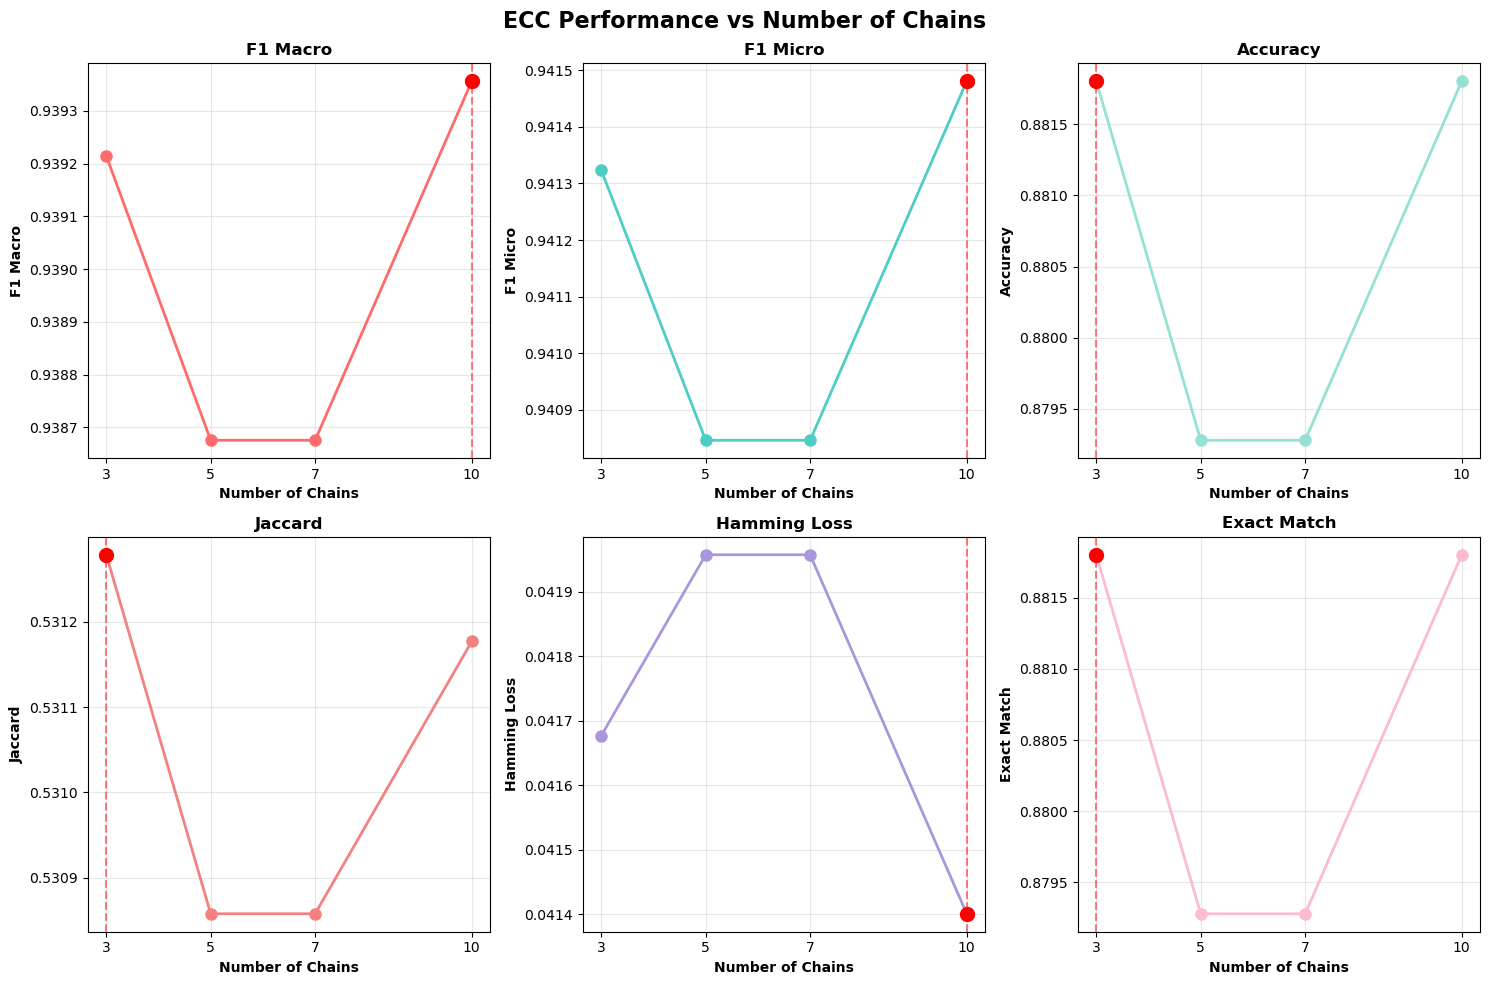


✓ Comparison plot saved: chain_count_comparison.png


In [9]:
# ============================================
# STEP 10: COMPARE RESULTS AND SELECT BEST
# ============================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Convert results to DataFrame
comparison_df = pd.DataFrame([
    {
        'Chains': r['n_chains'],
        'F1 Macro': r['f1_macro'],
        'F1 Micro': r['f1_micro'],
        'Accuracy': r['accuracy'],
        'Jaccard': r['jaccard'],
        'Hamming Loss': r['hamming_loss'],
        'Exact Match': r['exact_match']
    }
    for r in chain_comparison_results
])

print("\n" + "="*70)
print("📊 CHAIN COUNT COMPARISON TABLE")
print("="*70)
print(comparison_df.to_string(index=False))

# Identify best configuration based on F1 Macro
best_idx = comparison_df['F1 Macro'].idxmax()
best_chains = comparison_df.loc[best_idx, 'Chains']

print("\n" + "="*70)
print("🏆 BEST CONFIGURATION")
print("="*70)
print(f"  Optimal chains:     {int(best_chains)}")
print(f"  F1 Macro:          {comparison_df.loc[best_idx, 'F1 Macro']:.4f}")
print(f"  F1 Micro:          {comparison_df.loc[best_idx, 'F1 Micro']:.4f}")
print(f"  Jaccard:           {comparison_df.loc[best_idx, 'Jaccard']:.4f}")
print(f"  Accuracy:          {comparison_df.loc[best_idx, 'Accuracy']:.4f}")

# Visualize comparison
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
fig.suptitle('ECC Performance vs Number of Chains', fontsize=16, fontweight='bold')

metrics = ['F1 Macro', 'F1 Micro', 'Accuracy', 'Jaccard', 'Hamming Loss', 'Exact Match']
colors = ['#FF6B6B', '#4ECDC4', '#95E1D3', '#F38181', '#AA96DA', '#FCBAD3']

for idx, (metric, color) in enumerate(zip(metrics, colors)):
    row = idx // 3
    col = idx % 3
    ax = axes[row, col]
    
    ax.plot(comparison_df['Chains'], comparison_df[metric], 
            marker='o', linewidth=2, markersize=8, color=color)
    ax.set_xlabel('Number of Chains', fontweight='bold')
    ax.set_ylabel(metric, fontweight='bold')
    ax.set_title(metric, fontweight='bold')
    ax.grid(alpha=0.3)
    ax.set_xticks(comparison_df['Chains'])
    
    # Highlight best
    if metric != 'Hamming Loss':  # Higher is better
        best_val = comparison_df[metric].max()
        best_chain = comparison_df.loc[comparison_df[metric].idxmax(), 'Chains']
    else:  # Lower is better
        best_val = comparison_df[metric].min()
        best_chain = comparison_df.loc[comparison_df[metric].idxmin(), 'Chains']
    
    ax.axvline(best_chain, color='red', linestyle='--', alpha=0.5)
    ax.scatter([best_chain], [best_val], color='red', s=100, zorder=5)

plt.tight_layout()
plt.savefig('chain_count_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"\n✓ Comparison plot saved: chain_count_comparison.png")

In [10]:
# ============================================
# STEP 11: PERFORMANCE GAIN vs TIME ANALYSIS
# ============================================

print("\n" + "="*70)
print("⏱  PERFORMANCE GAIN vs TIME COST ANALYSIS")
print("="*70)

# Calculate improvement over baseline (3 chains)
baseline_f1 = comparison_df.loc[comparison_df['Chains'] == 3, 'F1 Macro'].values[0]

analysis_df = pd.DataFrame({
    'Chains': comparison_df['Chains'],
    'F1 Macro': comparison_df['F1 Macro'],
    'Improvement vs 3 chains (%)': ((comparison_df['F1 Macro'] - baseline_f1) / baseline_f1 * 100),
    'Relative Training Time': comparison_df['Chains'] / 3,
    'Time Cost (approx min)': comparison_df['Chains'] * 4  # ~4 min per chain with CV
})

print(analysis_df.to_string(index=False))

# Calculate efficiency (performance gain per unit time)
analysis_df['Efficiency Score'] = (
    analysis_df['Improvement vs 3 chains (%)'] / analysis_df['Relative Training Time']
)

print(f"\n EFFICIENCY ANALYSIS (Performance Gain / Training Time):")
print(analysis_df[['Chains', 'Efficiency Score']].to_string(index=False))

most_efficient = analysis_df.loc[analysis_df['Efficiency Score'].idxmax(), 'Chains']
print(f"\n Most efficient configuration: {int(most_efficient)} chains")


⏱  PERFORMANCE GAIN vs TIME COST ANALYSIS
 Chains  F1 Macro  Improvement vs 3 chains (%)  Relative Training Time  Time Cost (approx min)
      3  0.939215                     0.000000                1.000000                      12
      5  0.938675                    -0.057418                1.666667                      20
      7  0.938675                    -0.057418                2.333333                      28
     10  0.939356                     0.015072                3.333333                      40

 EFFICIENCY ANALYSIS (Performance Gain / Training Time):
 Chains  Efficiency Score
      3          0.000000
      5         -0.034451
      7         -0.024608
     10          0.004522

 Most efficient configuration: 10 chains


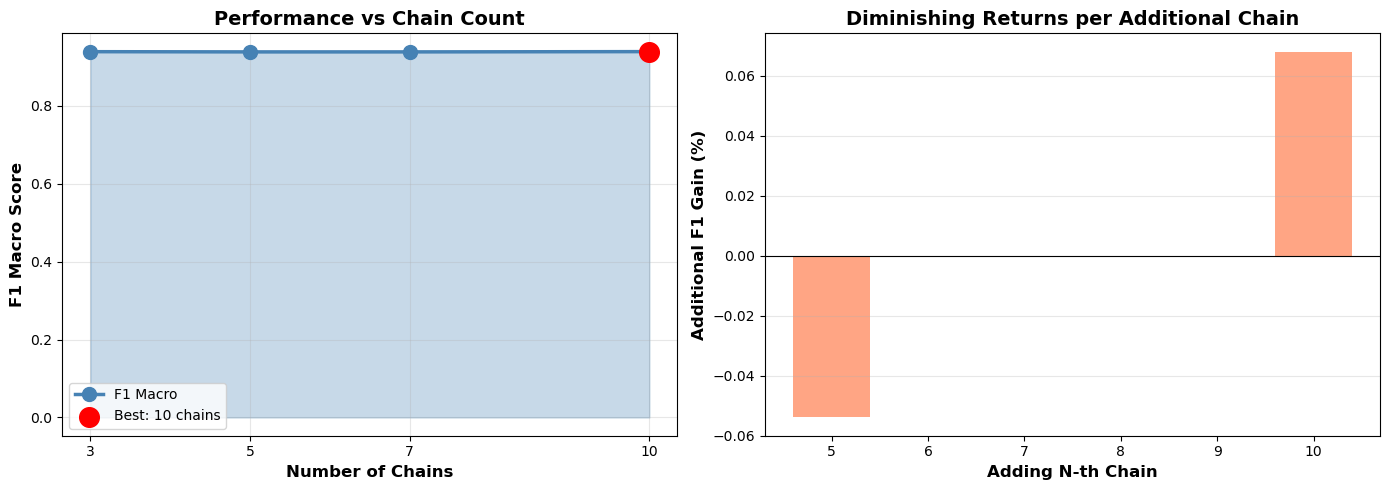


✓ Diminishing returns plot saved: diminishing_returns_analysis.png


In [11]:
# ============================================
# STEP 12: VISUALIZE DIMINISHING RETURNS
# ============================================

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Left plot: F1 Score vs Chains
ax1.plot(comparison_df['Chains'], comparison_df['F1 Macro'], 
         marker='o', linewidth=2.5, markersize=10, color='steelblue', label='F1 Macro')
ax1.fill_between(comparison_df['Chains'], 
                  comparison_df['F1 Macro'], 
                  alpha=0.3, color='steelblue')
ax1.set_xlabel('Number of Chains', fontsize=12, fontweight='bold')
ax1.set_ylabel('F1 Macro Score', fontsize=12, fontweight='bold')
ax1.set_title('Performance vs Chain Count', fontsize=14, fontweight='bold')
ax1.grid(alpha=0.3)
ax1.set_xticks(comparison_df['Chains'])

# Mark best
best_chain_val = comparison_df.loc[best_idx, 'Chains']
best_f1_val = comparison_df.loc[best_idx, 'F1 Macro']
ax1.scatter([best_chain_val], [best_f1_val], color='red', s=200, zorder=5, 
            label=f'Best: {int(best_chain_val)} chains')
ax1.legend()

# Right plot: Marginal gain per additional chain
marginal_gains = comparison_df['F1 Macro'].diff().fillna(0) * 100  # % improvement
ax2.bar(comparison_df['Chains'][1:], marginal_gains[1:], color='coral', alpha=0.7)
ax2.set_xlabel('Adding N-th Chain', fontsize=12, fontweight='bold')
ax2.set_ylabel('Additional F1 Gain (%)', fontsize=12, fontweight='bold')
ax2.set_title('Diminishing Returns per Additional Chain', fontsize=14, fontweight='bold')
ax2.grid(axis='y', alpha=0.3)
ax2.axhline(0, color='black', linewidth=0.8)

plt.tight_layout()
plt.savefig('diminishing_returns_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"\n✓ Diminishing returns plot saved: diminishing_returns_analysis.png")

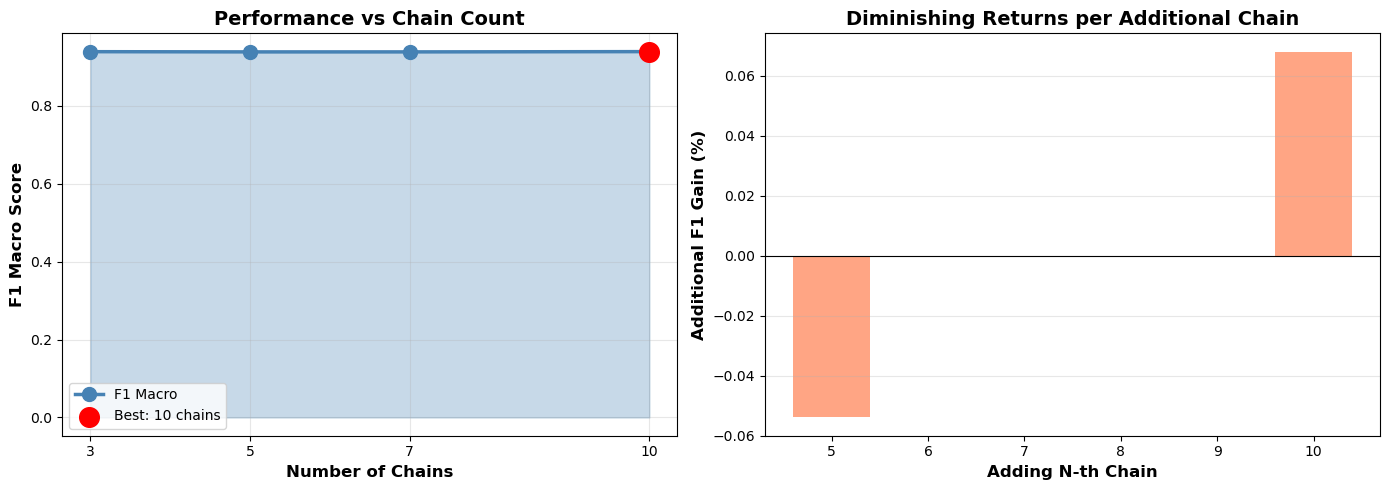


✓ Diminishing returns plot saved: diminishing_returns_analysis.png


In [12]:
# ============================================
# STEP 12: VISUALIZE DIMINISHING RETURNS
# ============================================

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Left plot: F1 Score vs Chains
ax1.plot(comparison_df['Chains'], comparison_df['F1 Macro'], 
         marker='o', linewidth=2.5, markersize=10, color='steelblue', label='F1 Macro')
ax1.fill_between(comparison_df['Chains'], 
                  comparison_df['F1 Macro'], 
                  alpha=0.3, color='steelblue')
ax1.set_xlabel('Number of Chains', fontsize=12, fontweight='bold')
ax1.set_ylabel('F1 Macro Score', fontsize=12, fontweight='bold')
ax1.set_title('Performance vs Chain Count', fontsize=14, fontweight='bold')
ax1.grid(alpha=0.3)
ax1.set_xticks(comparison_df['Chains'])

# Mark best
best_chain_val = comparison_df.loc[best_idx, 'Chains']
best_f1_val = comparison_df.loc[best_idx, 'F1 Macro']
ax1.scatter([best_chain_val], [best_f1_val], color='red', s=200, zorder=5, 
            label=f'Best: {int(best_chain_val)} chains')
ax1.legend()

# Right plot: Marginal gain per additional chain
marginal_gains = comparison_df['F1 Macro'].diff().fillna(0) * 100  # % improvement
ax2.bar(comparison_df['Chains'][1:], marginal_gains[1:], color='coral', alpha=0.7)
ax2.set_xlabel('Adding N-th Chain', fontsize=12, fontweight='bold')
ax2.set_ylabel('Additional F1 Gain (%)', fontsize=12, fontweight='bold')
ax2.set_title('Diminishing Returns per Additional Chain', fontsize=14, fontweight='bold')
ax2.grid(axis='y', alpha=0.3)
ax2.axhline(0, color='black', linewidth=0.8)

plt.tight_layout()
plt.savefig('diminishing_returns_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"\n✓ Diminishing returns plot saved: diminishing_returns_analysis.png")

In [13]:
# ============================================
# STEP 13: TRAIN FINAL MODEL WITH OPTIMAL CHAIN COUNT
# ============================================

print("\n" + "="*70)
print(f"🎯 TRAINING FINAL MODEL WITH OPTIMAL CONFIGURATION")
print("="*70)
print(f"  Selected chains: {int(best_chains)}")
print(f"  Expected F1:     {comparison_df.loc[best_idx, 'F1 Macro']:.4f}")

# Get best configuration
best_result = chain_comparison_results[best_idx]

# Train final model on full dataset
final_model = EnsembleClassifierChain(xgb_model, n_chains=int(best_chains))
final_model.fit(X, y)

print("\n✓ Final model trained on all 398 samples")
print(f"  This model uses {int(best_chains)} chains")
print(f"  Ready for deployment")


🎯 TRAINING FINAL MODEL WITH OPTIMAL CONFIGURATION
  Selected chains: 10
  Expected F1:     0.9394

  Training 10 classifier chains...
    ✓ Chain 1/10 trained
    ✓ Chain 2/10 trained
    ✓ Chain 3/10 trained
    ✓ Chain 4/10 trained
    ✓ Chain 5/10 trained
    ✓ Chain 6/10 trained
    ✓ Chain 7/10 trained
    ✓ Chain 8/10 trained
    ✓ Chain 9/10 trained
    ✓ Chain 10/10 trained

✓ Final model trained on all 398 samples
  This model uses 10 chains
  Ready for deployment



 FEATURE IMPORTANCE ANALYSIS
  Extracting feature importance from all chains...

 TOP 20 MOST IMPORTANT FEATURES:
              Feature  Importance
NC_003197_3814002_A>G    0.156990
             blaTEM-1    0.119913
NC_003197_2077267_A>T    0.100809
          aph(3'')-Ib    0.055948
NC_003197_1821749_G>A    0.046485
           YNQWLLVGRK    0.037226
           AKGEQLLFKA    0.032567
                 sul2    0.030109
NC_003197_3437381_A>T    0.022442
           TYNQWLLVGR    0.021650
            gyrA_S83Y    0.018647
NC_003197_3477121_G>A    0.017409
NC_003197_4562245_A>G    0.016345
           NQWLLVGRKT    0.015706
NC_003197_1535805_C>T    0.014265
NC_003197_3670138_T>G    0.014227
NC_003197_3847325_A>G    0.014204
           GAAPETSLSV    0.012625
           AGAVTAAIEM    0.008726
                 mdsA    0.007993


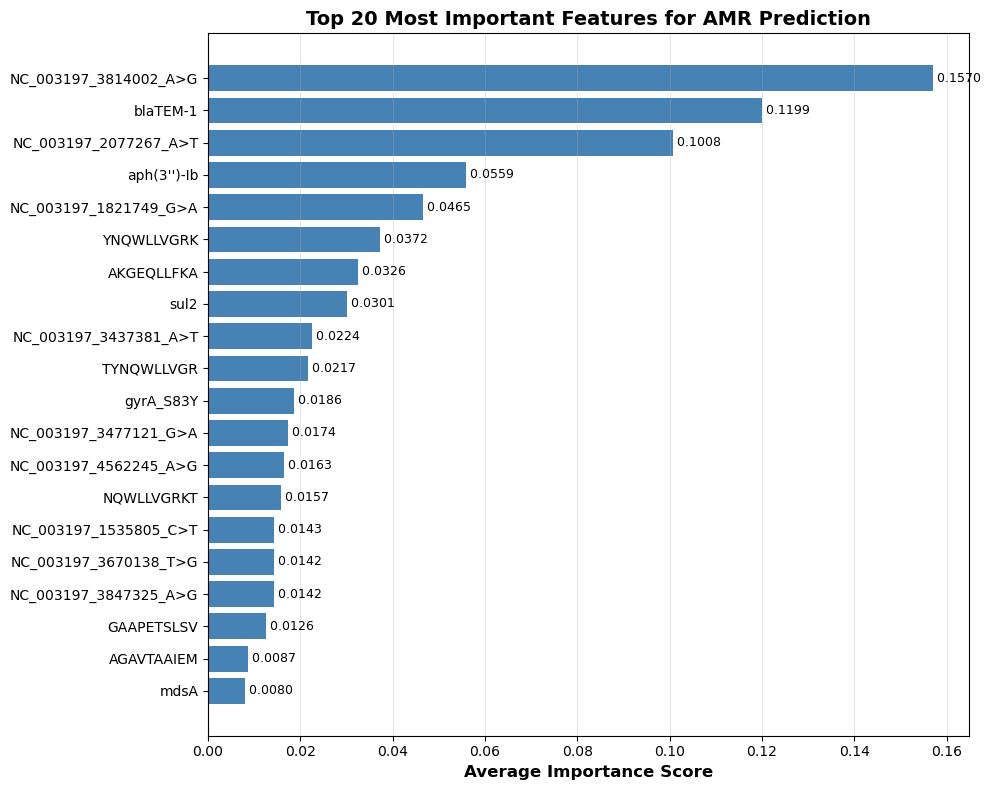


✓ Feature importance plot saved: feature_importance_top20_20260319_081405.png
✓ Full feature importance saved: feature_importance_full_20260319_081405.csv

📈 Feature Importance Statistics:
  Total features analyzed: 9009
  Features with importance > 0: 254
  Max importance: 0.156990
  Mean importance: 0.000111
  Top 20 cumulative importance: 0.7643


In [19]:
# ============================================
# STEP 14: EXTRACT FEATURE IMPORTANCE (TOP 20) - CORRECTED
# ============================================

print("\n" + "="*70)
print(" FEATURE IMPORTANCE ANALYSIS")
print("="*70)
from datetime import datetime

# For ECC, we extract importance from the FIRST model in each chain
# (which uses only original features, not chained predictions)
all_importances = []

print("  Extracting feature importance from all chains...")
for chain_idx, chain in enumerate(final_model.chains):
    # Get the first estimator in the chain (predicts first antibiotic)
    # This one uses only the original features (not augmented with predictions)
    first_estimator = chain.estimators_[0]
    
    # Get feature importance from this XGBoost model
    if hasattr(first_estimator, 'feature_importances_'):
        importance = first_estimator.feature_importances_
        all_importances.append(importance)
    else:
        print(f" Chain {chain_idx + 1} estimator has no feature_importances_")

# Average importance across all chains
if len(all_importances) > 0:
    avg_importance = np.mean(all_importances, axis=0)
    
    # Verify shape matches number of features
    if len(avg_importance) != X.shape[1]:
        print(f"   Warning: Importance shape ({len(avg_importance)}) doesn't match features ({X.shape[1]})")
        print(f"  Using first chain's first estimator only...")
        avg_importance = final_model.chains[0].estimators_[0].feature_importances_
    
    # Create DataFrame
    feature_importance_df = pd.DataFrame({
        'Feature': X.columns,
        'Importance': avg_importance
    })
    
    # Sort by importance
    feature_importance_df = feature_importance_df.sort_values('Importance', ascending=False)
    
    # Display top 20
    print("\n TOP 20 MOST IMPORTANT FEATURES:")
    print("="*70)
    top_20 = feature_importance_df.head(20)
    print(top_20.to_string(index=False))
    
    # Visualize top 20
    fig, ax = plt.subplots(figsize=(10, 8))
    
    top_20_sorted = top_20.sort_values('Importance', ascending=True)
    ax.barh(range(len(top_20_sorted)), top_20_sorted['Importance'], color='steelblue')
    ax.set_yticks(range(len(top_20_sorted)))
    ax.set_yticklabels(top_20_sorted['Feature'], fontsize=10)
    ax.set_xlabel('Average Importance Score', fontweight='bold', fontsize=12)
    ax.set_title('Top 20 Most Important Features for AMR Prediction', 
                 fontweight='bold', fontsize=14)
    ax.grid(axis='x', alpha=0.3)
    
    # Add value labels on bars
    for i, v in enumerate(top_20_sorted['Importance']):
        ax.text(v, i, f' {v:.4f}', va='center', fontsize=9)
    
    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    plt.tight_layout()
    plt.savefig(f'feature_importance_top20_{timestamp}.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    print(f"\n✓ Feature importance plot saved: feature_importance_top20_{timestamp}.png")
    
    # Save full feature importance to CSV
    feature_importance_df.to_csv(f'feature_importance_full_{timestamp}.csv', index=False)
    print(f"✓ Full feature importance saved: feature_importance_full_{timestamp}.csv")
    
    # Calculate importance statistics
    print(f"\n📈 Feature Importance Statistics:")
    print(f"  Total features analyzed: {len(feature_importance_df)}")
    print(f"  Features with importance > 0: {(feature_importance_df['Importance'] > 0).sum()}")
    print(f"  Max importance: {feature_importance_df['Importance'].max():.6f}")
    print(f"  Mean importance: {feature_importance_df['Importance'].mean():.6f}")
    print(f"  Top 20 cumulative importance: {top_20['Importance'].sum():.4f}")
    
else:
    print("ERROR: Could not extract feature importances")
    feature_importance_df = None

In [20]:
# ============================================
# STEP 15: SAVE MODEL AND ALL RESULTS
# ============================================

import pickle
from datetime import datetime
import os

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

# Save final model
model_filename = f"xgboost_ecc_{int(best_chains)}chains_model_{timestamp}.pkl"
with open(model_filename, 'wb') as f:
    pickle.dump(final_model, f)

# Save chain comparison results
comparison_filename = f"chain_comparison_results_{timestamp}.csv"
comparison_df.to_csv(comparison_filename, index=False)

# Save detailed metadata
metadata = {
    'optimal_chains': int(best_chains),
    'all_chain_results': chain_comparison_results,
    'best_metrics': best_result,
    'comparison_table': comparison_df.to_dict(),
    'n_samples': len(X),
    'n_features': X.shape[1],
    'antibiotics': ANTIBIOTIC_LABELS,
    'trained_date': datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
    'random_state': RANDOM_STATE
}

metadata_filename = f"model_metadata_{timestamp}.pkl"
with open(metadata_filename, 'wb') as f:
    pickle.dump(metadata, f)

print("\n" + "="*70)
print("💾 FILES SAVED")
print("="*70)
print(f"  Model:                    {model_filename}")
print(f"  Comparison CSV:           {comparison_filename}")
print(f"  Metadata:                 {metadata_filename}")
print(f"  Chain comparison plot:    chain_count_comparison.png")
print(f"  Diminishing returns plot: diminishing_returns_analysis.png")
print(f"  Feature importance plot:  feature_importance_top20_{timestamp}.png")
print(f"  Feature importance CSV:   feature_importance_full_{timestamp}.csv")
print(f"\n  Model size: {os.path.getsize(model_filename) / (1024*1024):.2f} MB")


💾 FILES SAVED
  Model:                    xgboost_ecc_10chains_model_20260319_081412.pkl
  Comparison CSV:           chain_comparison_results_20260319_081412.csv
  Metadata:                 model_metadata_20260319_081412.pkl
  Chain comparison plot:    chain_count_comparison.png
  Diminishing returns plot: diminishing_returns_analysis.png
  Feature importance plot:  feature_importance_top20_20260319_081412.png
  Feature importance CSV:   feature_importance_full_20260319_081412.csv

  Model size: 8.65 MB


In [22]:
# ============================================
# STEP 16: GENERATE COMPREHENSIVE SUMMARY REPORT
# ============================================

print("\n" + "="*70)
print(" FINAL MODEL OPTIMIZATION REPORT")
print("="*70)

report = f"""
{'='*70}
AMR PREDICTION MODEL - OPTIMIZATION REPORT
{'='*70}

CHAIN COUNT OPTIMIZATION SUMMARY:
{'='*70}

CONFIGURATIONS TESTED:
{comparison_df.to_string(index=False)}

OPTIMAL CONFIGURATION:
{'='*70}
Best chain count:       {int(best_chains)}
F1 Macro:              {comparison_df.loc[best_idx, 'F1 Macro']:.4f}
F1 Micro:              {comparison_df.loc[best_idx, 'F1 Micro']:.4f}
Jaccard Score:         {comparison_df.loc[best_idx, 'Jaccard']:.4f}
Accuracy:              {comparison_df.loc[best_idx, 'Accuracy']:.4f}
Precision (macro):     {best_result['precision_macro']:.4f}
Recall (macro):        {best_result['recall_macro']:.4f}
Exact Match:           {comparison_df.loc[best_idx, 'Exact Match']:.4f}
Hamming Loss:          {comparison_df.loc[best_idx, 'Hamming Loss']:.4f}

DIMINISHING RETURNS ANALYSIS:
{'='*70}
"""

for i in range(1, len(marginal_gains)):
    if i == 0:
        continue
    chains_added = comparison_df.loc[i, 'Chains']
    gain = marginal_gains.iloc[i]
    report += f"Adding chain {int(chains_added):2d}: +{gain:.3f}% F1 improvement\n"

report += f"""
EFFICIENCY ANALYSIS:
{'='*70}
{analysis_df.to_string(index=False)}

DATASET INFORMATION:
{'='*70}
Total samples:          {len(X)}
Total features:         {X.shape[1]}
Antibiotics predicted:  {len(ANTIBIOTIC_LABELS)}

PER-ANTIBIOTIC PERFORMANCE (F1 SCORES):
{'='*70}
"""

for antibiotic, f1 in sorted(best_result['per_antibiotic_f1'].items(), 
                              key=lambda x: x[1], reverse=True):
    report += f"{antibiotic:40s} {f1:.4f}\n"

report += f"""
TOP 5 MOST IMPORTANT FEATURES:
{'='*70}
"""

for idx, row in feature_importance_df.head(5).iterrows():
    report += f"{row['Feature']:40s} {row['Importance']:.6f}\n"

report += f"""
CONCLUSION:
{'='*70}
Using {int(best_chains)} chains provides the optimal balance of performance 
and training time for this AMR prediction task.

Performance improvement from 3 → {int(best_chains)} chains: 
  {((comparison_df.loc[best_idx, 'F1 Macro'] - baseline_f1) / baseline_f1 * 100):.2f}%

This model is ready for deployment in clinical AMR prediction systems.

{'='*70}
Model training and optimization completed successfully!
Timestamp: {datetime.now().strftime("%Y-%m-%d %H:%M:%S")}
{'='*70}
"""

print(report)

# Save report
report_filename = f"optimization_report_{timestamp}.txt"
with open(report_filename, 'w', encoding='utf-8') as f:
    f.write(report)

print(f"\n✓ Optimization report saved: {report_filename}")
print("\n ALL STEPS COMPLETED SUCCESSFULLY!")


 FINAL MODEL OPTIMIZATION REPORT

AMR PREDICTION MODEL - OPTIMIZATION REPORT

CHAIN COUNT OPTIMIZATION SUMMARY:

CONFIGURATIONS TESTED:
 Chains  F1 Macro  F1 Micro  Accuracy  Jaccard  Hamming Loss  Exact Match
      3  0.939215  0.941323  0.881803 0.531279      0.041677     0.881803
      5  0.938675  0.940846  0.879278 0.530858      0.041958     0.879278
      7  0.938675  0.940846  0.879278 0.530858      0.041958     0.879278
     10  0.939356  0.941481  0.881803 0.531177      0.041401     0.881803

OPTIMAL CONFIGURATION:
Best chain count:       10
F1 Macro:              0.9394
F1 Micro:              0.9415
Jaccard Score:         0.5312
Accuracy:              0.8818
Precision (macro):     0.9714
Recall (macro):        0.9113
Exact Match:           0.8818
Hamming Loss:          0.0414

DIMINISHING RETURNS ANALYSIS:
Adding chain  5: +-0.054% F1 improvement
Adding chain  7: +0.000% F1 improvement
Adding chain 10: +0.068% F1 improvement

EFFICIENCY ANALYSIS:
 Chains  F1 Macro  Improveme

In [23]:
import xgboost as xgb
print(f"XGBoost version during training: {xgb.__version__}")

XGBoost version during training: 3.1.3


In [24]:
import sklearn
print(sklearn.__version__)


1.4.2
